## Description
This notebook generates visualizations and outputs them to results/visualisations to better understand how the model results come about. It is structured like:
1. Imports
2. Setting technology colors for some visualisations
3. All functions
4. Loading model runs
5. Inspecting results and using of functions for visualisations

# 1

### Imports

In [55]:
from pathlib import Path
import re
import warnings
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

years = [2025, 2030, 2040, 2050]
gas_multipliers = [1, 3, 5.5, 8]
electrolysis_multipliers = [1, 0.75, 0.5, 0.25]

out_dir = Path("results/final_results")
carbon_dir = Path("results/carbon_runs_final")
hydrogen_routes = ["SMR", "SMR with CCS", "Electrolysis"]

# 2

### Setting technology colors for visualization

In [56]:
tech_colors = {
    "CCGT": "#D98242",
    "Biomass plant": "#71A45B",
    "Nuclear plant": "#9670BA",
    "Solar PV": "#E8BC38",
    "Wind turbine - onshore": "#42A9AD",
    "Wind turbine - offshore": "#2474B5",
    "BEV": "#36A6A1",
    "ICE car": "#A67C60",
    "Residential Appliance": "#B0B5BC",
    "Battery": "#6C68BC",
    "CCGT CCS": "#A95332",
    "Biomass plant CCS": "#35794A",
    "Residential gas boiler": "#C17B42",
    "Residential heat pump": "#B17FB1",
    "Industrial machinery - fossil": "#B18060",
    "Industrial machinery - fossil CCS": "#825C50",
    "Industrial machinery - electricity": "#5188C3",
    "Industrial HTP - fossil": "#A65F50",
    "Industrial HTP - fossil CCS": "#71566C",
    "BEV - existing": "#36A6A1",
    "ICE car - existing": "#A67C60",
    "CCGT - existing": "#D98242",
    "Residential gas boiler - existing": "#C17B42",
    "Industrial machinery - fossil - existing": "#B18060",
    "Industrial HTP - fossil - existing": "#A65F50",
    "SMR": "#858585",
    "SMR with CCS": "#3478B9",
    "Electrolysis": "#16A085",
    "SMR - existing": "#8585858D",
    "SMR with CCS - existing": "#3479B99D",
    "Electrolysis - existing": "#16A08489",
}

# 3

### Handy plotting functions from the final course notebook

In [57]:
# Handy plotting functions. 
# Note that these are good to quickly diagnose your runs, 
# but for your final presentation and paper you will need
# nicer-looking plots, following the data-visualization 
# guidelines we discussed in class!

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1, 1)
    fig.set_size_inches(10, 4)

    df = scen.statistics.energy_balance(bus_carrier='Hydrogen')
    df = df.set_index(df.index.get_level_values(1)).T
    df.plot(kind='bar', stacked='True', rot=0, colormap="tab20", ax=ax)
    ax.set_ylabel('MWh')
    ax.set_title(scen.name)

    fig.tight_layout()

def plot_main_ebs_complete(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential electricity',
            'Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP']): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20",ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20", ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


### Helper functions and data visualisation functions

In [58]:
def get_tech_color(name):
    """Resolve technology labels, including tuples and investment vintages."""
    names = name if isinstance(name, tuple) else [name]
    for item in names:
        tech = str(item).strip()
        if tech in tech_colors:
            return tech_colors[tech]
        tech = re.sub(r"_\d+$", "", tech)
        if tech in tech_colors:
            return tech_colors[tech]
    return "#BDBDBD"


def hydrogen_production(n):
    """Annual H₂ production by route, in TWh; existing assets included."""
    links = n.links.index[n.links.bus1 == "Hydrogen"]
    production = (
        (-n.links_t.p1[links])
        .mul(n.snapshot_weightings.generators, axis=0)
        .groupby(level=0).sum().T
    )
    routes = n.links.loc[links, "carrier"].str.replace(
        " - existing", "", regex=False
    )
    return (
        production.groupby(routes).sum().T
        .reindex(columns=hydrogen_routes, fill_value=0.0) / 1e6
    )


def cumulative_co2(n, year=2050):
    """End-of-period atmosphere emissions, in MtCO₂."""
    return n.stores_t.e["CO2 atmosphere"].loc[year].iloc[-1] / 1e6

def plot_balance(n, carrier, ax):
    """Plot a signed energy balance, grouped by technology carrier."""
    balance = n.statistics.energy_balance(bus_carrier=carrier)
    if isinstance(balance.index, pd.MultiIndex):
        level = "carrier" if "carrier" in balance.index.names else 1
        balance = balance.groupby(level=level).sum()
    data = balance.T
    data.plot.bar(stacked=True, rot=0, ax=ax, colormap="tab20",)
    ax.set_title(carrier)
    unit = ("Mvkm" if carrier == "Transportation" else "tCO₂" if "CO2" in carrier else "MWh")
    ax.set_ylabel(unit)
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        borderaxespad=0,
        frameon=False,
        title="Technology",
    )


def plot_cost_emissions(results):
    """Discounted model objective versus the 2050 cumulative co2 emissions."""
    fig, ax = plt.subplots(figsize=(9, 6))
    for gas, group in results.loc[results["Year"] == 2050].groupby("Gas multiplier"):
        ax.scatter(
            group["Cumulative CO2 (Mt)"],
            group["System objective (trillion €)"],
            label=f"Gas price {gas:g}×", s=80,
        )
    ax.set(
        title="System costs and cumulative emissions",
        xlabel="Cumulative net CO₂ by 2050 (MtCO₂)",
        ylabel="Discounted model objective (trillion €)",
    )
    ax.legend(title="Gas-price assumption")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

def plot_carbon_sensitivity(carbon_results, year):
    """CO2-price sensitivity and cumulative emissions for a selected model year."""

    data = carbon_results.xs(year, level="Year").sort_index()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    colors = [get_tech_color('SMR'), get_tech_color('SMR with CCS'), get_tech_color('Electrolysis')]

    # hydrogen production mix
    data[['SMR', 'SMR with CCS', 'Electrolysis']].plot(ax=axes[0], marker='o', color=colors)

    axes[0].set_title(f'{year} hydrogen mix vs carbon price')
    axes[0].set_xlabel('Carbon price (€/tCO2)')
    axes[0].set_ylabel('Hydrogen production share (%)')
    axes[0].set_ylim(-10, 110)
    axes[0].grid(alpha=0.3)

    # CO2 atmosphere store
    data['Cumulative CO2'].plot(ax=axes[1], marker='o', color='tab:red', legend=False)

    axes[1].set_title(f'Cumulative CO2 emissions through {year}')
    axes[1].set_xlabel('Carbon price (€/tCO2)')
    axes[1].set_ylabel('CO2 atmosphere store (MtCO2)')
    axes[1].grid(alpha=0.3)

    fig.tight_layout()

    return fig



def plot_hydrogen_share_heatmaps(
    results,
    years,
    gas_multipliers,
    electrolysis_multipliers,
    out_dir,
    technology="Electrolysis",
    share_column=None,
):
    """Plot and save one hydrogen technology's shares across cost scenarios.

    By default, reads the column '<technology> share (%)'. Use share_column
    if your results table uses a different column name. Shares must already
    be expressed as percentages (0–100), not fractions.

    Returns the figure, axes array, and filtered results table.
    Does not reload networks or calculate new production shares.
    """
    years = list(years)
    gas_levels = sorted(set(gas_multipliers))
    capex_levels = sorted(set(electrolysis_multipliers), reverse=True)
    if not years or not gas_levels or not capex_levels:
        raise ValueError("Years and both multiplier lists must be nonempty.")

    if share_column is None:
        share_column = f"{technology} share (%)"

    required = ["Year", "Gas multiplier", "CAPEX multiplier", share_column]
    missing_columns = [column for column in required if column not in results.columns]
    if missing_columns:
        raise ValueError(
            f"Missing results columns: {missing_columns}. "
            "Provide share_column for an existing percentage column, or add "
            "the required technology shares to results first."
        )

    heatmap_data = results.loc[
        results["Year"].isin(years)
        & results["Gas multiplier"].isin(gas_levels)
        & results["CAPEX multiplier"].isin(capex_levels)
    ].copy()

    scenario_columns = ["Year", "Gas multiplier", "CAPEX multiplier"]
    if heatmap_data.duplicated(scenario_columns).any():
        raise ValueError("Multiple results rows found for the same year/cost scenario.")

    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#eeeeee")
    norm = Normalize(0, 100)
    fig, axes = plt.subplots(
        1, len(years), figsize=(3.3 * len(years) + 1, 4.8),
        sharey=True, squeeze=False, layout="constrained",
    )
    axes = axes.ravel()

    for ax, year in zip(axes, years):
        matrix = (
            heatmap_data.loc[heatmap_data["Year"] == year]
            .pivot(
                index="Gas multiplier", columns="CAPEX multiplier",
                values=share_column,
            )
            .reindex(index=gas_levels, columns=capex_levels)
        )
        values = matrix.to_numpy(dtype=float)
        image = ax.imshow(
            np.ma.masked_invalid(values), cmap=cmap, norm=norm,
            origin="lower", aspect="equal",
        )
        ax.set_title(str(year), fontweight="bold")
        ax.set_xticks(range(len(capex_levels)), [f"×{v:g}" for v in capex_levels])
        ax.set_yticks(range(len(gas_levels)), [f"×{v:g}" for v in gas_levels])
        ax.set_xlabel("Electrolysis CAPEX multiplier")
        ax.tick_params(which="major", length=0, pad=7)

        for (row, col), value in np.ndenumerate(values):
            missing = not np.isfinite(value)
            # Use contrasting text on both dark and light heatmap cells.
            if missing:
                text_color = "#555555"
            else:
                red, green, blue, _ = cmap(norm(value))
                luminance = 0.2126 * red + 0.7152 * green + 0.0722 * blue
                text_color = "black" if luminance > 0.55 else "white"
            ax.text(
                col, row, "—" if missing else f"{value:.0f}%",
                ha="center", va="center", fontsize=10, color=text_color,
            )

        ax.set_xticks(np.arange(len(capex_levels) + 1) - 0.5, minor=True)
        ax.set_yticks(np.arange(len(gas_levels) + 1) - 0.5, minor=True)
        ax.grid(which="minor", color="white", linewidth=2)
        ax.tick_params(which="minor", bottom=False, left=False)
        for spine in ax.spines.values():
            spine.set_visible(False)

    axes[0].set_ylabel("Gas price multiplier")
    fig.colorbar(
        image, ax=axes.tolist(), shrink=0.8, pad=0.02,
        label=f"{technology} share of hydrogen production (%)",
    )
    fig.suptitle(
        f"{technology} share across cost scenarios", fontsize=14,
    )

    output_dir = Path(out_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    filename = re.sub(r"[^a-z0-9]+", "_", technology.lower()).strip("_")
    filename = f"{filename}_share_heatmaps"
    fig.savefig(output_dir / f"{filename}.png", dpi=300, bbox_inches="tight")
    heatmap_data.to_csv(output_dir / f"{filename}.csv", index=False)
    plt.show()

    return fig, axes, heatmap_data


def plot_electricity_supply_mix(
    networks,
    years_to_plot=None,
    electricity_bus='Electricity',
    exclude_link_carriers=None,
    technology_labels=None,
):
    """Extract, plot and save annual electricity supply shares.

    Uses already loaded networks and the notebook's np, pd, plt and re imports.
    Snapshot weights must represent hours within each modeled year.
    Includes generators and positive injections at Link output ports.
    StorageUnits are excluded; storage-discharge Links remain included unless
    their carriers are specified in exclude_link_carriers.

    Returns the figure, two-dimensional axes array and full results table.
    """
    output_dir = Path('results/visualisations')    
    exclude_link_carriers = set() if exclude_link_carriers is None else exclude_link_carriers
    technology_labels = {} if technology_labels is None else technology_labels
    output_dir.mkdir(parents=True, exist_ok=True)

    def technology_label(row, component_name):
        """Group build-year vintages using carrier, with a name fallback."""
        carrier = row.get('carrier', '')
        if pd.isna(carrier) or str(carrier).strip() == '':
            carrier = re.sub(r'_\d{4}$', '', str(component_name))
        carrier = str(carrier)
        return technology_labels.get(carrier, carrier)

    # ------------------------- EXTRACT --------------------------
    records = []
    if not networks:
        raise ValueError('No already loaded networks found in networks.')

    for scenario, n in networks.items():
        if electricity_bus not in n.buses.index:
            warnings.warn(f'Skipping {scenario}: no {electricity_bus!r} bus')
            continue

        if isinstance(n.snapshots, pd.MultiIndex):
            snapshot_years = n.snapshots.get_level_values(0)
        elif isinstance(n.snapshots, pd.DatetimeIndex):
            snapshot_years = n.snapshots.year
        else:
            warnings.warn(f'Skipping {scenario}: cannot identify snapshot years')
            continue

        model_years = sorted(pd.unique(snapshot_years))
        if years_to_plot is not None:
            model_years = [y for y in model_years if y in years_to_plot]

        weights_all = n.snapshot_weightings['generators']
        generator_names = n.generators.index[n.generators['bus'].eq(electricity_bus)]

        # Prepare labels and output tables once per network, not once per year.
        sources = [
            (technology_label(n.generators.loc[name], name), n.generators_t.p[name])
            for name in generator_names
        ]
        output_ports = sorted(
            [c for c in n.links.columns if re.fullmatch(r'bus[1-9]\d*', str(c))],
            key=lambda c: int(c[3:]),
        )
        for port in output_ports:
            link_names = n.links.index[
                n.links[port].eq(electricity_bus)
                & ~n.links['carrier'].isin(exclude_link_carriers)
            ]
            flows = n.links_t['p' + port[3:]]
            sources.extend(
                (technology_label(n.links.loc[name], name), -flows[name])
                for name in link_names
            )

        for year in model_years:
            snapshots = n.snapshots[snapshot_years == year]
            weights = weights_all.loc[snapshots]
            production = {}

            # Clip each snapshot: withdrawals must not count as supply.
            for label, output in sources:
                mwh = float(output.loc[snapshots].clip(lower=0).mul(weights).sum())
                production[label] = production.get(label, 0.0) + mwh

            total_mwh = sum(production.values())
            if total_mwh <= 0:
                warnings.warn(f'No electricity supply: {scenario}, {year}')

            for label, mwh in production.items():
                records.append({
                    'Scenario': scenario,
                    'Year': int(year),
                    'Technology': label,
                    'Electricity_MWh': mwh,
                    'Electricity_TWh': mwh / 1e6,
                    'Share_Pct': 100 * mwh / total_mwh if total_mwh > 0 else np.nan,
                    'Total_Electricity_TWh': total_mwh / 1e6,
                })

    if not records:
        raise ValueError('No electricity supply data extracted; check networks and bus name.')

    df_mix = pd.DataFrame(records).sort_values(['Scenario', 'Year', 'Technology'])
    csv_path = 'results/visualisations/electricity_supply_mix_by_year.csv'
    df_mix.to_csv(csv_path, index=False)

    # --------------------------- PLOT ---------------------------
    # The extraction already records each scenario-year's total supply.
    plot_df = df_mix.loc[df_mix['Total_Electricity_TWh'] > 0]
    if plot_df.empty:
        raise ValueError('All scenario-year groups have zero electricity supply.')

    technology_totals = plot_df.groupby('Technology')['Electricity_MWh'].sum()
    technologies = technology_totals[technology_totals > 0].sort_values(
        ascending=False
    ).index.tolist()
    scenarios = sorted(plot_df['Scenario'].unique())

    cmap = plt.get_cmap('tab20')
    colors = {tech: cmap(i % 20) for i, tech in enumerate(technologies)}
    ncols = 4
    nrows = 4
    legend_cols = min(5, len(technologies))
    legend_rows = (len(technologies) + legend_cols - 1) // legend_cols
    legend_height = 0.45 * legend_rows + 0.4

    fig, axes = plt.subplots(
        nrows=nrows, ncols=ncols, squeeze=False,
        figsize=(5.2 * ncols, 3.8 * nrows + legend_height),
    )

    for ax, scenario in zip(axes.flat, scenarios):
        subset = plot_df[plot_df['Scenario'].eq(scenario)]
        shares = subset.pivot(
            index='Year', columns='Technology', values='Share_Pct',
        ).reindex(columns=technologies, fill_value=0).fillna(0).sort_index()

        x = np.arange(len(shares))
        bottom = np.zeros(len(shares))
        for technology in technologies:
            values = shares[technology].to_numpy()
            ax.bar(
                x, values, bottom=bottom, width=0.7,
                color=colors[technology], label=technology,
            )
            bottom += values

        ax.set_title(scenario, fontsize=10)
        ax.set_xticks(x)
        ax.set_xticklabels(shares.index.astype(str))
        ax.set_xlabel('Modeled year')
        ax.set_ylabel('Share of electricity supply (%)')
        ax.set_ylim(0, 100)
        ax.set_axisbelow(True)
        ax.grid(axis='y', alpha=0.25)

    for ax in list(axes.flat)[len(scenarios):]:
        ax.set_visible(False)

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.suptitle('Electricity supply mix by modeled year', fontsize=14)
    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.01),
        ncol=legend_cols,
        frameon=False,
        fontsize=14,
        handlelength=2.5,
        handleheight=1.2,
        columnspacing=1.5,
        labelspacing=0.8,
    )
    fig.tight_layout(rect=[0, legend_height / fig.get_figheight(), 1, 0.95])

    figure_path = 'results/visualisations/electricity_supply_shares_by_year.png'
    fig.savefig(figure_path, dpi=300, bbox_inches='tight')

    print(f'CSV saved: {csv_path}')
    print(f'Figure saved: {figure_path}')
    print(df_mix.head(15).to_string(index=False))
    plt.show()

    return fig, axes, df_mix


def plot_electricity_demand_growth(results_dir="results"):
    """Plot electricity consumption from 2025 to 2050 for different gas-price scenarios, including a baseline without hydrogen. Returns annual electricity consumption in TWh."""

    scenarios = {
        "Baseline (no hydrogen)":
            "no_hydro/gas_x1_elec_x1_no_hydro.nc",

        "Gas price ×1 (with hydrogen)":
            "final_results/gas_x1_elec_x1.nc",

        "Gas price ×3":
            "final_results/gas_x3_elec_x1.nc",

        "Gas price ×5.5":
            "final_results/gas_x5.5_elec_x1.nc",

        "Gas price ×8":
            "final_results/gas_x8_elec_x1.nc",
    }

    results_dir = Path(results_dir)
    electricity_demand = {}

    for label, filename in scenarios.items():

        path = results_dir / filename

        if not path.exists():
            raise FileNotFoundError(f"Missing scenario: {path}")

        n = pypsa.Network(path)

        # no-hydrogen baseline
        if label == "Baseline (no hydrogen)":
            if "Hydrogen" in n.buses.index:
                raise ValueError(
                    f"The no-hydrogen baseline still contains "
                    f"a hydrogen bus: {path}"
                )

        # links that consume electricity
        electricity_links = n.links.index[n.links.bus0 == "Electricity"]

        # electricity consumption mw weighted by hours
        electricity_use = (n.links_t.p0[electricity_links] .clip(lower=0) .mul(n.snapshot_weightings.generators, axis=0))

        # aggregate by model year and convert MWh to TWh
        annual_demand = (electricity_use .groupby(level=0) .sum() .sum(axis=1) / 1e6)

        electricity_demand[label] = annual_demand

    demand_df = pd.DataFrame(electricity_demand).sort_index()

    fig, ax = plt.subplots(figsize=(11, 6))

    styles = {
        "Baseline (no hydrogen)": ("black", "--"),
        "Gas price ×1 (with hydrogen)": ("tab:blue", "-"),
        "Gas price ×3": ("tab:orange", "--"),
        "Gas price ×5.5": ("tab:green", "-."),
        "Gas price ×8": ("tab:red", ":"),
    }

    for label in demand_df.columns:

        values = demand_df[label]
        color, linestyle = styles[label]

        is_baseline = label == "Baseline (no hydrogen)"

        ax.plot(
            demand_df.index,
            values,
            color=color,
            linestyle=linestyle,
            marker="o",
            markerfacecolor="white" if is_baseline else color,
            markersize=8 if is_baseline else 6,
            linewidth=2.5,
            zorder=10 if is_baseline else 3,
            label=f"{label}"
        )

    ax.set_title("Growth in Electricity Demand, 2025–2050", fontsize=16, fontweight="bold", pad=20)
    ax.set_xlabel("Model year", fontsize=12)
    ax.set_ylabel("Electricity consumption (TWh/year)", fontsize=12)
    ax.set_xticks(demand_df.index)
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
    fig.tight_layout()
    plt.show()

    return demand_df


# 4

### Load saved models

In [59]:
if not out_dir.is_dir():
    raise FileNotFoundError(f"Results directory not found: {out_dir.resolve()}")

files = sorted(out_dir.glob("gas_x*_elec_x*.nc"))
if not files:
    raise FileNotFoundError(f"No gas/CAPEX scenarios found in {out_dir.resolve()}")

networks = {file.stem: pypsa.Network(file) for file in files}
print(f"Loaded {len(networks)} gas/CAPEX scenarios")

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.25' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.5' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x0.75' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x3_elec_x0.25' has buses, carriers, generators, link

Loaded 16 gas/CAPEX scenarios


# 5

### Turn the already solved networks into results tables

In [60]:
results = []


for name, n in networks.items():

    # only analyse gasprice/electrolyser CAPEX scenarios here
    if not name.startswith('gas_x'):
        continue

    # every link producing hydrogen
    h2_links = n.links.index[n.links.bus1 == 'Hydrogen']

    # h2 production is the -link output p1 so x snapshot hours = energy MWh
    production = (-n.links_t.p1[h2_links]).mul(n.snapshot_weightings.generators, axis=0)

    # sum production in each model year
    production = production.groupby(level=0).sum().T

    # combine existing and new production techs
    production['route'] = (n.links.loc[production.index, 'carrier'].str.replace(' - existing', '', regex=False))

    production = production.groupby('route').sum().T / 1e6

    # get gas price and electrolyser CAPEX multipliers
    parts = name.split('_')
    gas = float(parts[1].replace('x', ''))
    capex = float(parts[3].replace('x', ''))

    for y in years:

        grey = production.at[y, 'SMR']
        blue = production.at[y, 'SMR with CCS']
        electrolysis = production.at[y, 'Electrolysis']

        total = grey + blue + electrolysis

        results.append({
            'Scenario': name,
            'Year': y,
            'Gas multiplier': gas,
            'CAPEX multiplier': capex,
            'Grey': grey,
            'Blue': blue,
            'Electrolysis': electrolysis,
            'Electrolysis share (%)': 100 * electrolysis / total,
            'SMR share (%)': 100 * grey / total,
            'SMR with CCS share (%)': 100 * blue / total,
            'Cumulative CO2 (Mt)': (
                n.stores_t.e['CO2 atmosphere']
                .loc[y].iloc[-1] / 1e6
            ),
            'System objective (trillion €)': n.objective / 1e12
        })

results = pd.DataFrame(results)

display(results.round(2))

,Scenario,Year,Gas multiplier,CAPEX multiplier,Grey,Blue,Electrolysis,Electrolysis share (%),SMR share (%),SMR with CCS share (%),Cumulative CO2 (Mt),System objective (trillion €)
0,gas_x1_elec_x0.25,2025,1.0,0.25,23.21,1.38,0.00,0.00,94.37,5.63,79.50,2.49
1,gas_x1_elec_x0.25,2030,1.0,0.25,25.12,0.00,-0.00,-0.00,100.00,0.00,143.79,2.49
2,gas_x1_elec_x0.25,2040,1.0,0.25,26.02,0.00,0.00,0.00,100.00,0.00,203.55,2.49
3,gas_x1_elec_x0.25,2050,1.0,0.25,26.78,0.00,0.00,0.00,100.00,0.00,245.55,2.49
4,gas_x1_elec_x0.5,2025,1.0,0.50,23.21,1.38,0.00,0.00,94.37,5.63,79.50,2.49
...,...,...,...,...,...,...,...,...,...,...,...,...
59,gas_x8_elec_x0.75,2050,8.0,0.75,3.13,0.00,23.65,88.32,11.68,0.00,124.01,3.93
60,gas_x8_elec_x1,2025,8.0,1.00,24.59,0.00,0.00,0.01,99.99,0.00,56.20,3.94
61,gas_x8_elec_x1,2030,8.0,1.00,5.90,-0.00,19.22,76.51,23.49,-0.00,84.20,3.94
62,gas_x8_elec_x1,2040,8.0,1.00,4.79,0.00,21.22,81.58,18.42,0.00,105.64,3.94


### Generate heatmaps
Interaction between natural gas prices and electrolyser investment costs in determining the share of electrolysis in total hydrogen production. The 2025 through 2050 panels shows differences between early adoption and long-term technology choice. The bottom left cell represents the "business as usual" scenario, the bottom row represents the "internal incentives" scenario, the left-most column represents the "external gas shock" scenario, and the rest of the grid represents the synergies between the external gas shock and internal incentives in our model.

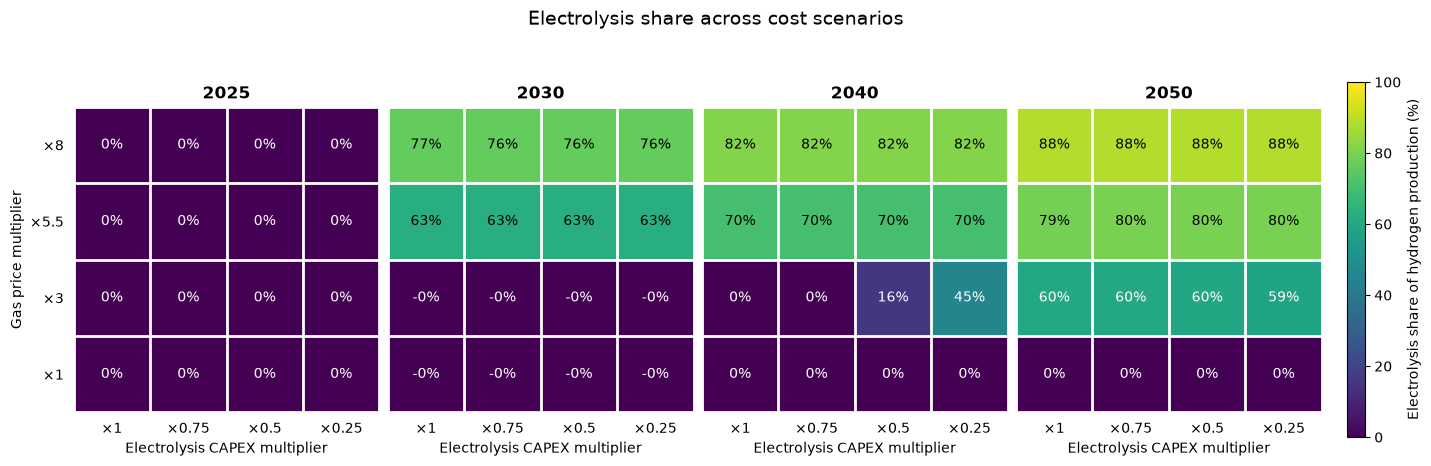

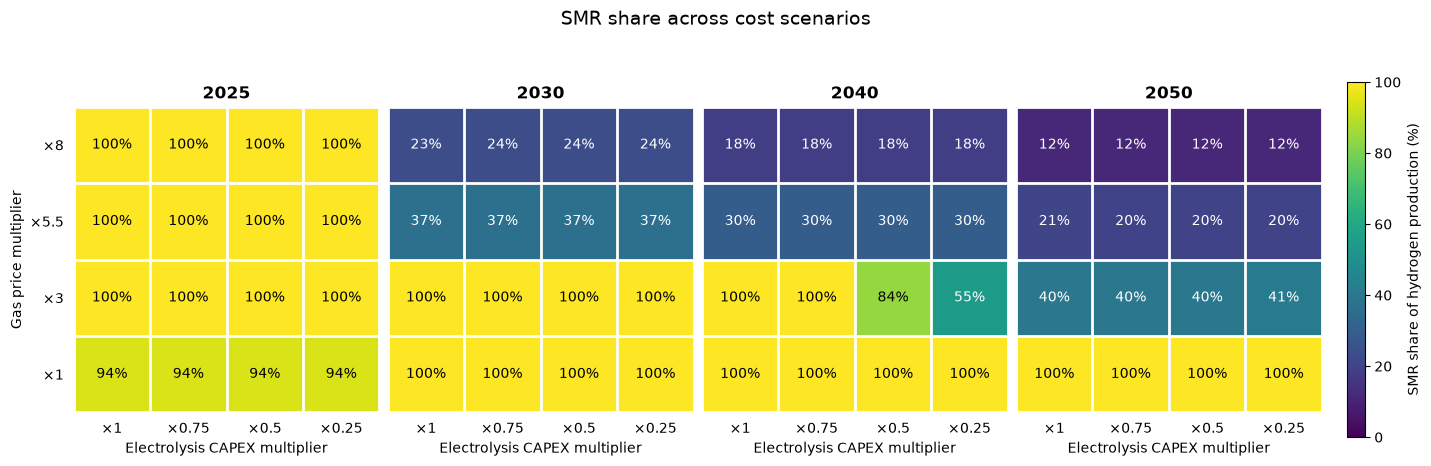

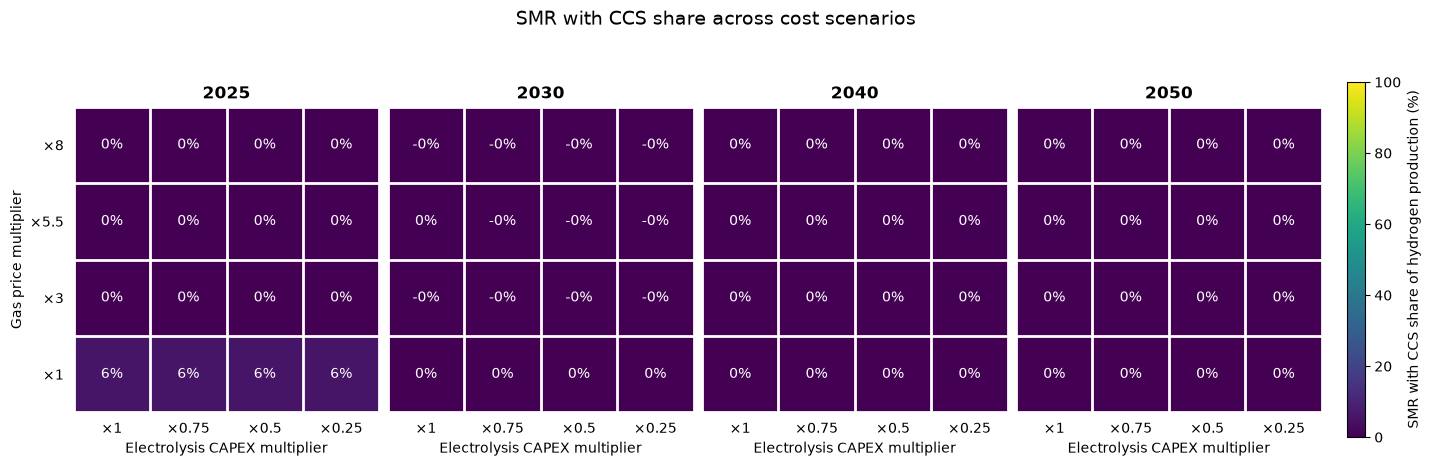

In [61]:
for technology in ["Electrolysis", "SMR", "SMR with CCS"]:
    fig, axes, heatmap_data = plot_hydrogen_share_heatmaps(
        results=results,
        years=years,
        gas_multipliers=gas_multipliers,
        electrolysis_multipliers=electrolysis_multipliers,
        out_dir="results/visualisations",
        technology=technology,
    )

### Determine the share of technologies in the model's electricity supply per scenario

CSV saved: results/visualisations/electricity_supply_mix_by_year.csv
Figure saved: results/visualisations/electricity_supply_shares_by_year.png
         Scenario  Year        Technology  Electricity_MWh  Electricity_TWh  Share_Pct  Total_Electricity_TWh
gas_x1_elec_x0.25  2025     Biomass plant     9.584605e+05         0.958460   2.976849              32.197145
gas_x1_elec_x0.25  2025 Biomass plant CCS     0.000000e+00         0.000000   0.000000              32.197145
gas_x1_elec_x0.25  2025              CCGT     0.000000e+00         0.000000   0.000000              32.197145
gas_x1_elec_x0.25  2025   CCGT - existing     2.387931e+03         0.002388   0.007417              32.197145
gas_x1_elec_x0.25  2025          CCGT CCS     0.000000e+00         0.000000   0.000000              32.197145
gas_x1_elec_x0.25  2025     Nuclear plant     0.000000e+00         0.000000   0.000000              32.197145
gas_x1_elec_x0.25  2025             Solar     1.892869e+07        18.928692  58.789972

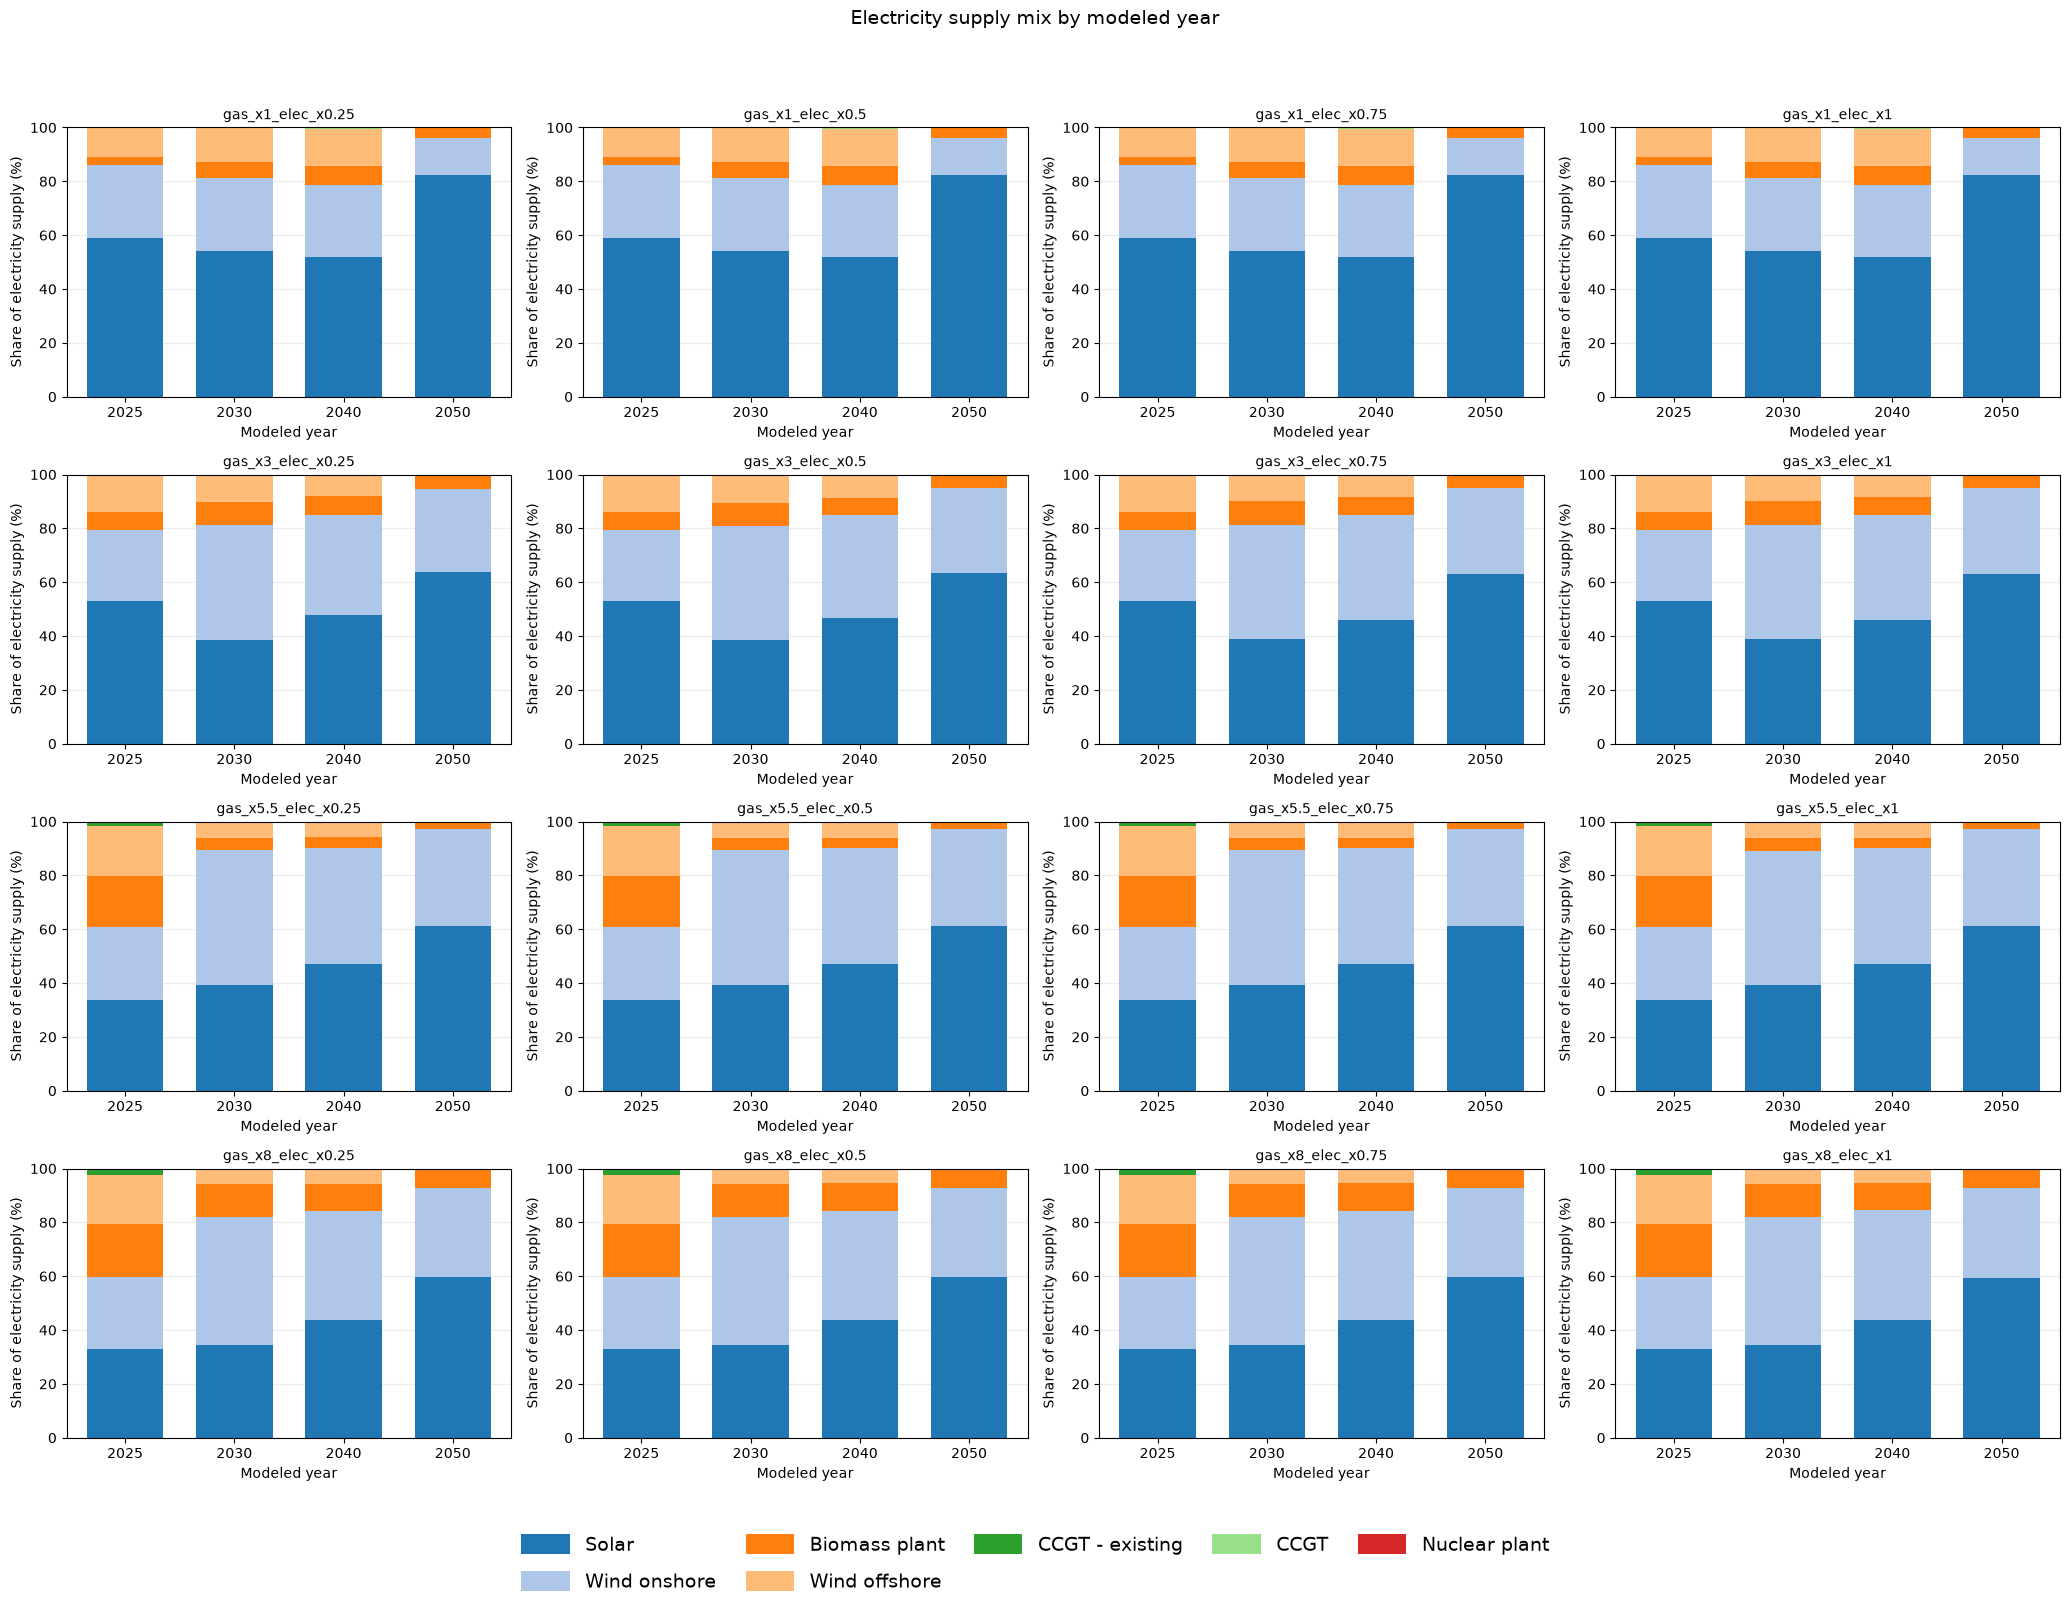

In [62]:
fig, axes, df_mix = plot_electricity_supply_mix(
    networks=networks,
)

### Dot plot
Relationship between cumulative atmospheric emissions and modelled discounted system costs under the gas price and electrolyser CAPEX scenarios. Each point corresponds to an optimised scenario.

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1_co2_0' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1_co2_100' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1_co2_101' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1_co2_102' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1_co2_103' has buses,

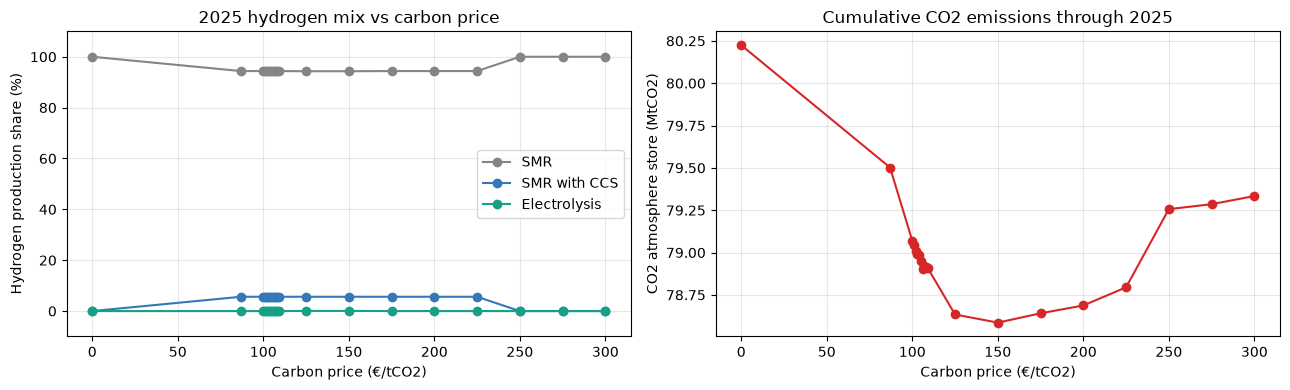

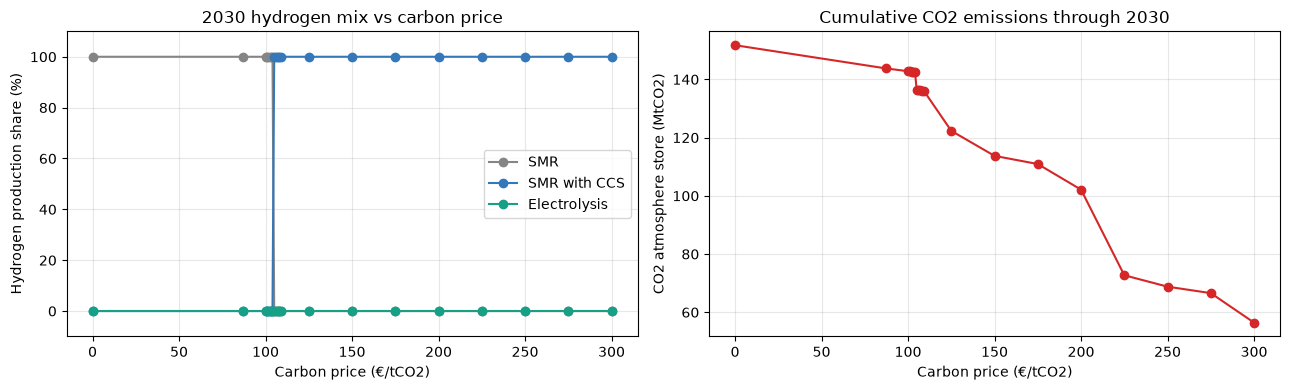

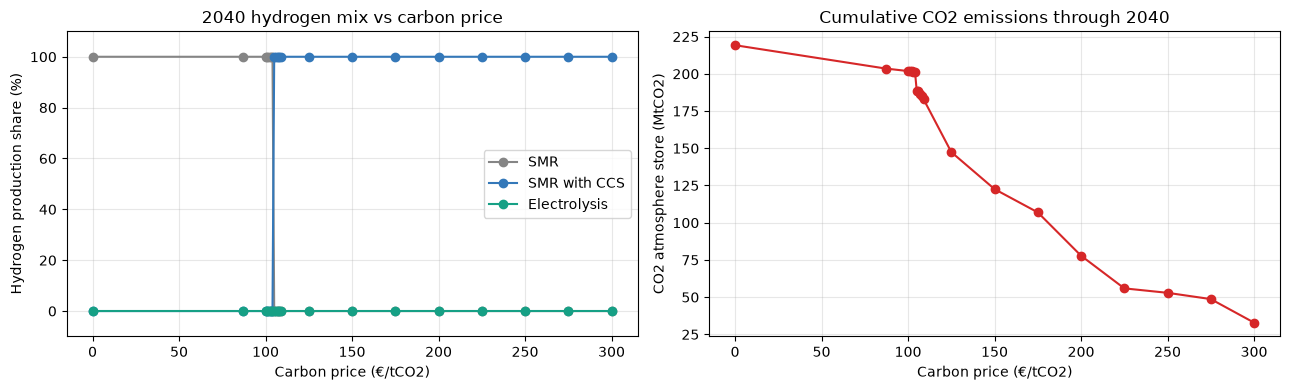

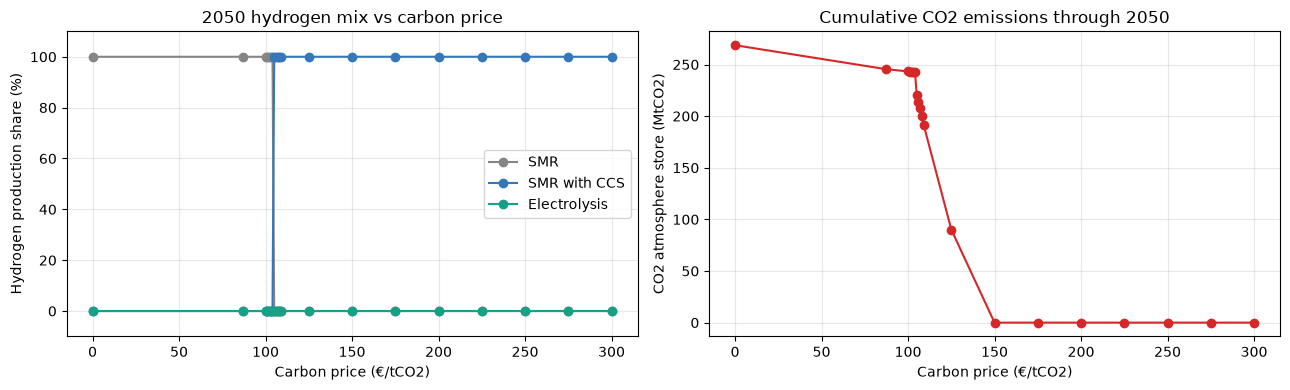

SMR  SMR with CCS  Electrolysis  Cumulative CO2
Year CO2 price                                                    
2025 0          100.00          0.00           0.0           80.22
     87          94.37          5.63           0.0           79.50
     100         94.37          5.63           0.0           79.07
     101         94.37          5.63           0.0           79.05
     102         94.37          5.63           0.0           79.01
...                ...           ...           ...             ...
2050 200          0.00        100.00           0.0            0.00
     225          0.00        100.00           0.0            0.00
     250          0.00        100.00           0.0            0.00
     275          0.00        100.00           0.0            0.00
     300          0.00        100.00           0.0            0.00

[80 rows x 4 columns]

In [63]:
carbon_files = sorted(carbon_dir.glob("*co2*.nc"))

if not carbon_files:
    raise FileNotFoundError(
        f"No carbon-price scenarios found in {carbon_dir.resolve()}"
    )

years = [2025, 2030, 2040, 2050]
carbon_records = []

for file in carbon_files:

    price = int(file.stem.rsplit("_", 1)[-1])
    n = pypsa.Network(file)

    # hydrogen production TWh/year for all model years
    production_by_year = hydrogen_production(n)

    for year in years:

        # hydrogen production for this year
        production = production_by_year.loc[year]

        total = production.sum()

        shares = (100 * production / total if total > 0 else production * np.nan)

        # CO2 atmosphere store at end of this model year
        co2 = cumulative_co2(n, year=year)

        carbon_records.append({
            "Year": year,
            "CO2 price": price,
            **shares.to_dict(),
            "Cumulative CO2": co2,
        })

# df with Year and CO2 price as indices
carbon_results = (pd.DataFrame(carbon_records) .set_index(["Year", "CO2 price"]) .sort_index())

if not carbon_results.index.is_unique:
    raise ValueError(
        "Multiple carbon-price scenarios have the same year and CO2 price.")

for year in years:
    fig = plot_carbon_sensitivity(carbon_results, year)
    plt.show()
    plt.close(fig)

display(carbon_results.round(2))


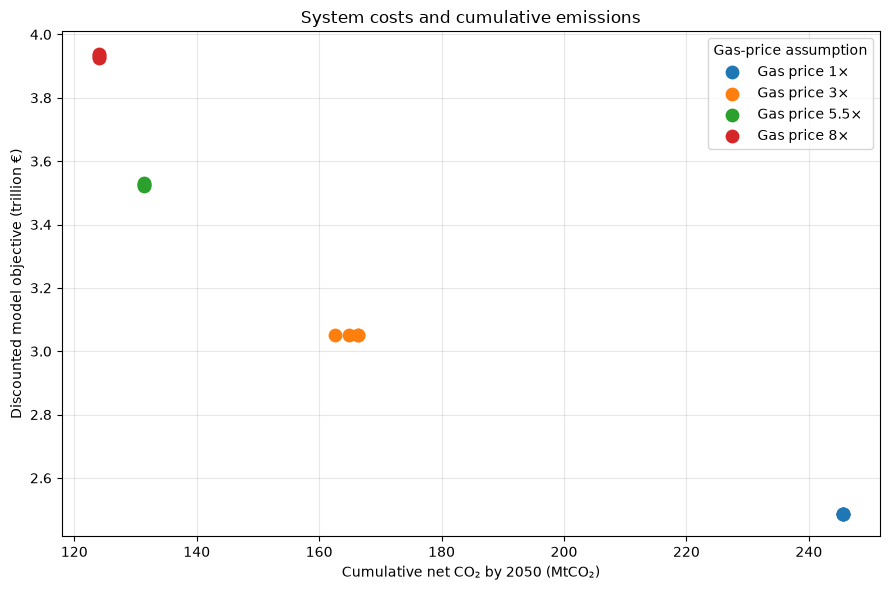

In [64]:
plot_cost_emissions(results)

### For checks, generate the energy balances for the default "business as usual" scenario

/var/folders/_s/3m5r3tk90cb5vvjhzy5smf0h0000gn/T/ipykernel_20567/2244058953.py:64: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


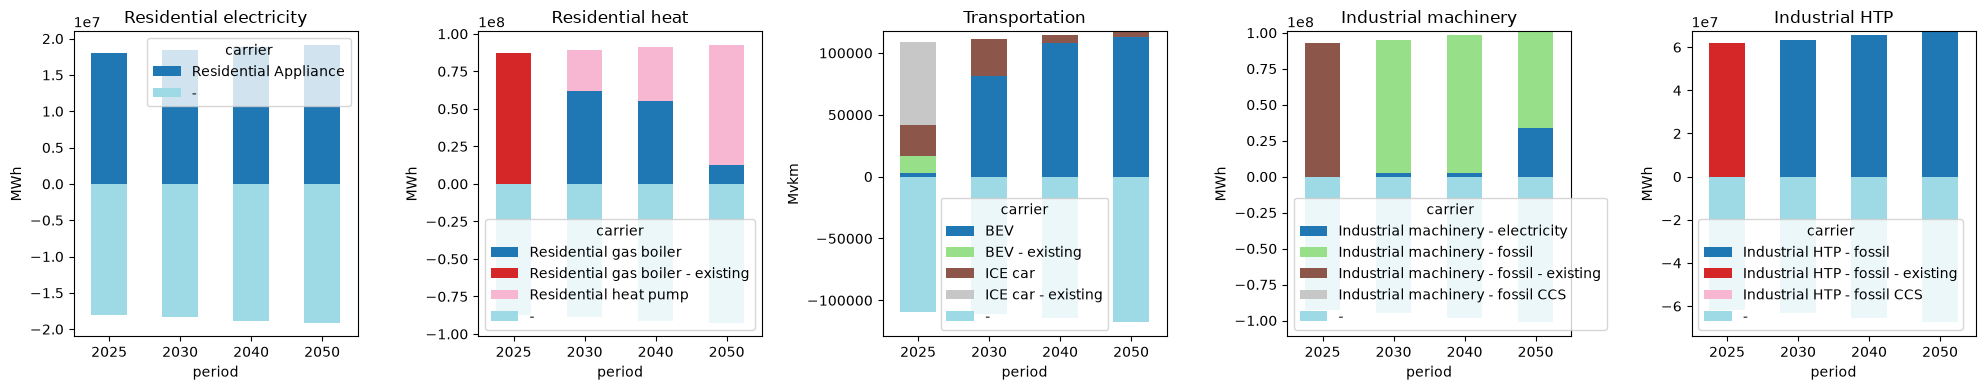

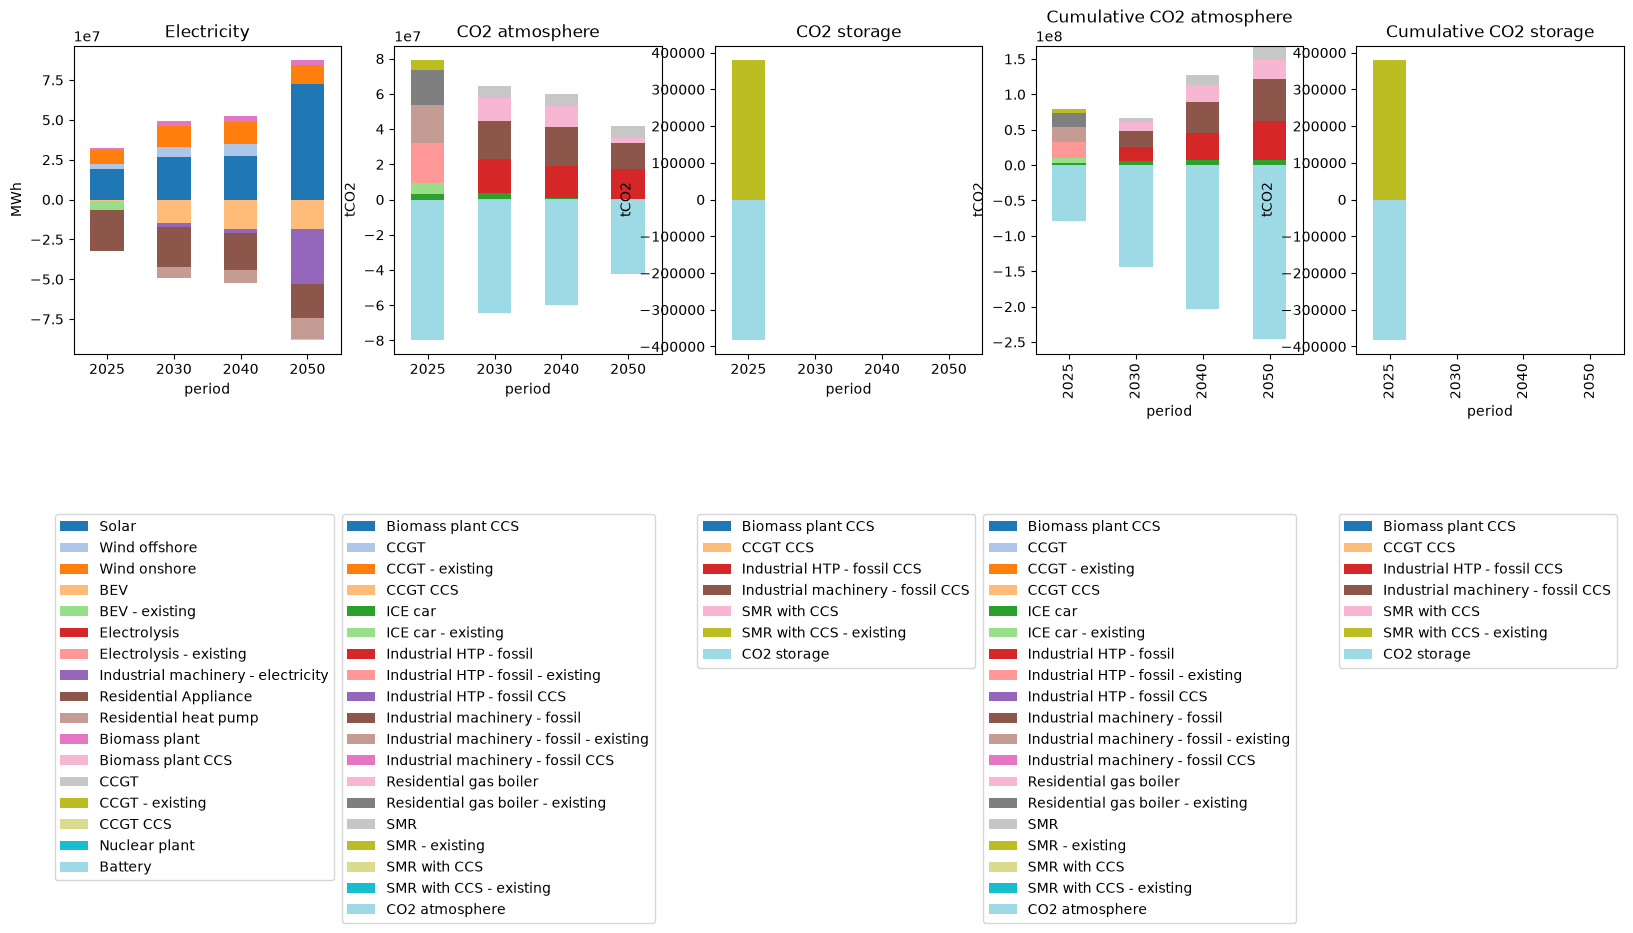

In [65]:
# plot energy balances for the the default gasprice/electrolyser CAPEX scenario (gas_x1_elec_x1.nc) and the carbon-price scenarios

n = networks["gas_x1_elec_x1"]
plot_main_ebs_complete(n)
plot_elc_emi(n)

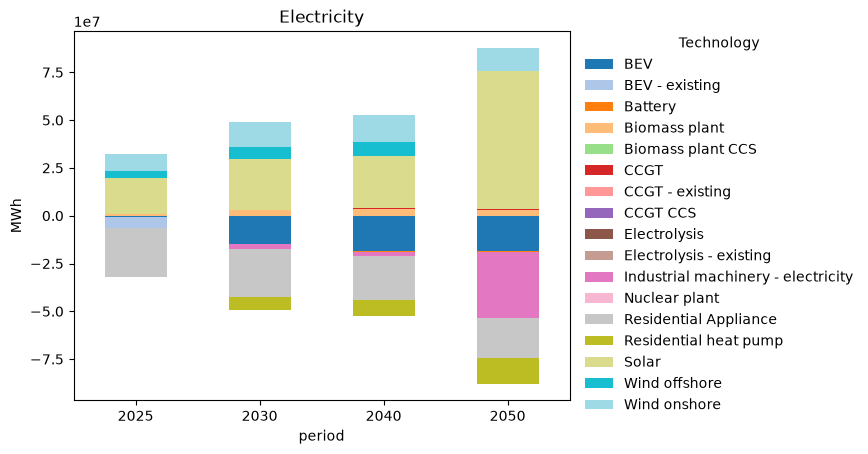

In [66]:
plot_balance(n, "Electricity", plt.gca())

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)


INFO:pypsa.network.io:Imported network 'baseline_no_hydrogen' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x1_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x3_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x5.5_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'gas_x8_elec_x1' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


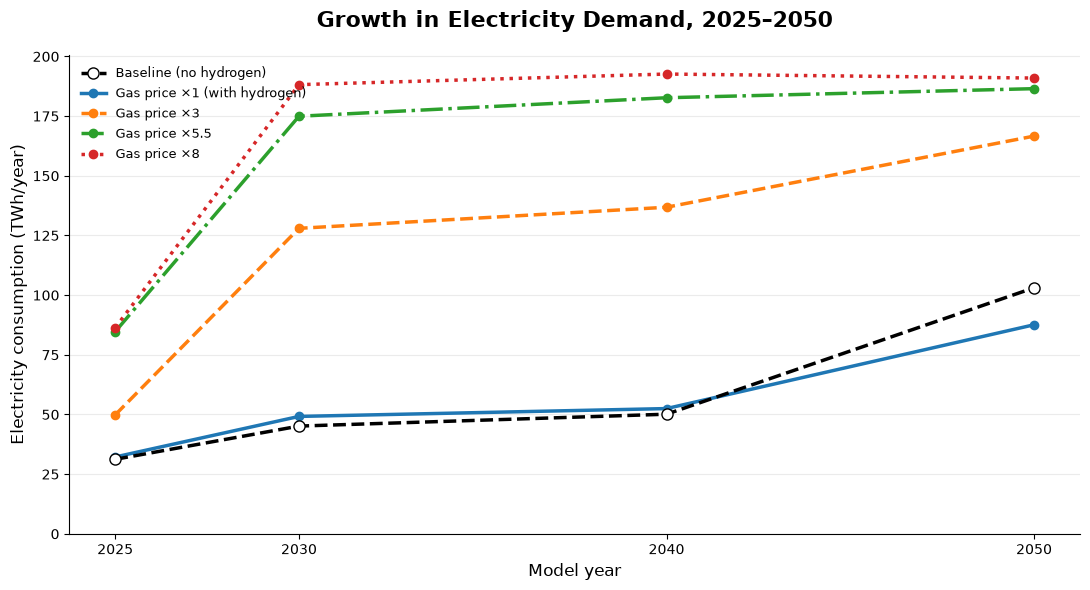

,Baseline (no hydrogen),Gas price ×1 (with hydrogen),Gas price ×3,Gas price ×5.5,Gas price ×8
period,,,,,
2025,31.22,32.20,49.84,84.72,86.36
2030,45.14,49.19,127.99,174.95,188.18
2040,50.12,52.48,136.83,182.70,192.63
2050,103.08,87.59,166.63,186.50,190.95


In [67]:

electricity_demand_df = plot_electricity_demand_growth()

display(electricity_demand_df.round(2))
